# MADA. Fase 2: Experimento Empírico

Este notebook implementa a instanciação empírica da Metodologia de Amplificação de Divergências Anotativas (MADA), utilizando o corpus MQD-1222, consolidado na Fase 1.

O experimento compara a concordância entre os rótulos dos grupos masculino e feminino com a concordância entre as predições de classificadores treinados separadamente a partir desses rótulos. A variação é quantificada por Δκ, permitindo examinar a preservação ou amplificação das divergências anotativas no aprendizado supervisionado.

### Verificação do ambiente (VS Code ou Google Colab)

In [1]:
import os
import sys

# 1. Detectar se o ambiente é o Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Ambiente detectado: Google Colab")
    REPO_URL = "https://github.com/alexfeitosa72/mada.git"
    REPO_NAME = "mada"

    # Clonar apenas se a pasta ainda não existir no ambiente virtual do Colab
    if not os.path.exists(REPO_NAME):
        print(f"📥 Clonando {REPO_NAME}...")
        !git clone {REPO_URL}
    
    # Entrar na pasta do repositório no Colab
    if os.getcwd().split('/')[-1] != REPO_NAME:
        os.chdir(REPO_NAME)
    
    print(f"Diretório de trabalho ajustado: {os.getcwd()}")
else:
    print(f"Ambiente detectado: Local (VS Code/Jupyter)")
    print(f"Mantendo diretório atual: {os.getcwd()}")

# 2. Listar arquivos de forma compatível (funciona em Windows, Mac, Linux e Colab)
print("\nArquivos na pasta raiz:")
print(os.listdir('.'))

Ambiente detectado: Local (VS Code/Jupyter)
Mantendo diretório atual: c:\Users\alexander.feitosa\Documents\Github\mada

Arquivos na pasta raiz:
['.git', '.gitignore', '.python-version', '.venv', 'dados', 'dependencias-antes-correcao.txt', 'fase1-tratamento-logs-ordem-historica.ipynb', 'fase1-tratamento-logs.ipynb', 'fase2-dados-empiricos.ipynb', 'fase3-dados-sinteticos.ipynb', 'fase4-resultados-gerais.ipynb', 'requirements-lock.txt', 'requirements.txt']


## 1. Setup e Configurações

In [2]:
# Importações
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
from datetime import datetime

# Scikit-learn
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)
from sklearn.base import clone

# Análise estatística
from scipy.stats import chi2_contingency

# Visualização
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

# Configurações
warnings.filterwarnings('ignore')

# ============================================================================
# ESTILO ACADÊMICO NATURE (azulado)
# ============================================================================
plt.style.use('seaborn-v0_8-whitegrid')

NATURE_BLUE = '#0C4A6E'
NATURE_BLUE_MED = '#0284C7'
NATURE_BLUE_LIGHT = '#38BDF8'
NATURE_GRAY = '#64748B'
NATURE_ACCENT = '#1E3A5F'

NATURE_PALETTE = [NATURE_BLUE, NATURE_BLUE_MED, NATURE_BLUE_LIGHT, NATURE_GRAY]

CORES_MODELOS_NATURE = {
    'SVM': '#0C4A6E',
    'NB': '#0284C7',
    'RF': '#0EA5E9',
    'LR': '#38BDF8'
}

COR_NEGATIVA = '#DC2626'
COR_NEUTRA = '#6B7280'
COR_POSITIVA = '#0284C7'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'regular',
    'axes.labelsize': 12,
    'axes.labelweight': 'regular',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--'
})

sns.set_palette(NATURE_PALETTE)
pd.options.display.float_format = '{:.4f}'.format

print("[OK] Bibliotecas importadas com sucesso.")
print("[OK] Estilo acadêmico Nature aplicado.")


[OK] Bibliotecas importadas com sucesso.
[OK] Estilo acadêmico Nature aplicado.


In [3]:
# ANTES: floats com ponto (f'{x:.4f}'), "κ_anot" com sublinhado literal, títulos em Title Case com " - " e " — "
# DEPOIS:
import matplotlib as mpl
mpl.rcParams['mathtext.fontset'] = 'cm'          # subscritos como no LaTeX
def vir(x, d=4, sinal=False):                    # vírgula decimal
    s = f'{x:+.{d}f}' if sinal else f'{x:.{d}f}'
    return s.replace('.', ',')
from matplotlib.ticker import FuncFormatter       # eixos com vírgula
fmt_eixo = FuncFormatter(lambda v, _: f'{v:.1f}'.replace('.', ','))
K_ANOT, K_PRED, DK = r'$\kappa_{\mathrm{anot}}$', r'$\kappa_{\mathrm{pred}}$', r'$\Delta\kappa$'
TITULO_NA_FIGURA = False   # a legenda do LaTeX já é o título; evita divergência entre os dois

In [4]:
def kap(sub, negrito=False):
    estilo = r'\mathbf' if negrito else r'\mathrm'
    return f'κ$_{{{estilo}{{{sub}}}}}$'

K_ANOT      = kap('anot')                 # legendas e texto corrido
K_PRED      = kap('pred')
K_ANOT_B    = kap('anot', negrito=True)   # eixos e títulos em negrito
K_PRED_B    = kap('pred', negrito=True)
DK          = 'Δκ'                        # sem subscrito, não precisa de mathtext

mpl.rcParams.update({
    'axes.labelsize': 12, 'axes.titlesize': 13,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 12, 'legend.title_fontsize': 12,
})
# legendas com κ: fontsize 12; anotações nas barras: 10 a 11

In [ ]:
SEED = 42
N_FOLDS = 5

DATA_DIR = Path("dados")
INPUT_FILE = DATA_DIR / "02-logs-processados" / "mqd-1222-majoritarias.csv"
RESULTS_DIR = DATA_DIR / "03-resultados-empiricos"
GRAFICOS_DIR = RESULTS_DIR / "graficos-empiricos"

# Garante a existência dos diretórios de saída
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)   # cinto de seguranca; a reprodutibilidade dos resultados
                       # NAO depende mais do estado global (bootstraps usam default_rng isolado)

CLASSE_MAP = {'negativa': -1, 'neutra': 0, 'positiva': 1}
CLASSE_REVERSO = {v: k for k, v in CLASSE_MAP.items()}

print("=" * 80)
print("CONFIGURAÇÕES")
print("=" * 80)
print(f"Seed: {SEED}")
print(f"K-Fold CV: {N_FOLDS} folds")
print(f"Arquivo: {INPUT_FILE}")
print("=" * 80)


CONFIGURAÇÕES
Seed: 42
K-Fold CV: 5 folds
Arquivo: dados\02-logs-processados\mqd-1222-majoritarias.csv


In [6]:
# Modelos de classificação (hiperparâmetros padrão)
modelos = {
    'SVM': SVC(kernel='linear', C=1.0, random_state=SEED),
    'NB': MultinomialNB(alpha=1.0),
    'RF': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    'LR': LogisticRegression(max_iter=1000, C=1.0, random_state=SEED, n_jobs=-1)
}

print("="*80)
print("MODELOS CONFIGURADOS")
print("="*80)
for nome, modelo in modelos.items():
    params = modelo.get_params()
    params_rel = {k: v for k, v in params.items() 
                  if k in ['C', 'alpha', 'kernel', 'n_estimators', 'solver', 'random_state']}
    print(f"\n{nome}:")
    for param, valor in params_rel.items():
        print(f"    {param}: {valor}")

MODELOS CONFIGURADOS

SVM:
    C: 1.0
    kernel: linear
    random_state: 42

NB:
    alpha: 1.0

RF:
    n_estimators: 100
    random_state: 42

LR:
    C: 1.0
    random_state: 42
    solver: lbfgs


## Módulo I. Concordância inicial

A concordância entre os rótulos consolidados por gênero é mensurada pelo κ de Cohen, estabelecendo a referência para a avaliação posterior das predições. A análise é complementada pela concordância observada, pelo teste qui-quadrado e pelo V de Cramér.

A incerteza do κ inicial é estimada por bootstrap, com 10.000 reamostragens e intervalo de confiança de 95%.

In [7]:
# Carregar dados
print("="*80)
print("MÓDULO I: BASELINE")
print("="*80)

df = pd.read_csv(INPUT_FILE, sep='\t')
print(f"\n[OK] {len(df)} frases carregadas.")
print(f"[OK] Colunas: {list(df.columns)}.")

df.head()

MÓDULO I: BASELINE

[OK] 1222 frases carregadas.
[OK] Colunas: ['frase', 'duracao_media_masculino', 'total_classificacoes_masculino', 'classificacao_majoritaria_masculino', 'votos_maioria_masculino', 'total_positiva_masculino', 'total_negativa_masculino', 'total_neutra_masculino', 'duracao_media_feminino', 'total_classificacoes_feminino', 'classificacao_majoritaria_feminino', 'votos_maioria_feminino', 'total_positiva_feminino', 'total_negativa_feminino', 'total_neutra_feminino', 'concordancia_grupos'].


,frase,duracao_media_masculino,total_classificacoes_masculino,classificacao_majoritaria_masculino,votos_maioria_masculino,total_positiva_masculino,total_negativa_masculino,total_neutra_masculino,duracao_media_feminino,total_classificacoes_feminino,classificacao_majoritaria_feminino,votos_maioria_feminino,total_positiva_feminino,total_negativa_feminino,total_neutra_feminino,concordancia_grupos
0,Comprei meu livro.,24.8965,4,negativa,4,0,4,0,29.0708,4,negativa,4,0,4,0,1
1,Confesso que aquilo me dava um prazer quase qu...,4.6967,4,negativa,3,0,3,1,6.6075,4,negativa,4,0,4,0,1
2,"Mais uma vez eu to aqui me lamentando, eu esto...",2.3243,4,neutra,3,1,0,3,10.0270,4,neutra,3,1,0,3,1
3,"Ela me fala coisas e depois diz que não falou,...",6.4900,4,positiva,4,4,0,0,8.5228,4,positiva,4,4,0,0,1
4,Eles brigaram e ela terminou com ele.,5.9215,4,negativa,4,0,4,0,9.7170,4,negativa,4,0,4,0,1


In [8]:
# Mapear classes para valores numéricos
y_masculino = df['classificacao_majoritaria_masculino'].map(CLASSE_MAP)
y_feminino = df['classificacao_majoritaria_feminino'].map(CLASSE_MAP)

print("\nMapeamento:")
for classe, valor in CLASSE_MAP.items():
    print(f"  {classe:>10} -> {valor:>2}")


Mapeamento:
    negativa -> -1
      neutra ->  0
    positiva ->  1


In [9]:
# Calcular métricas de concordância inicial
kappa_anot = cohen_kappa_score(y_masculino, y_feminino)
concordancia = np.mean(y_masculino == y_feminino)

contingency = pd.crosstab(y_masculino, y_feminino)
chi2, p_value, dof, expected = chi2_contingency(contingency)

n = len(y_masculino)
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

print(f"\nMétricas de Baseline:")
print(f"  κ_anot (Cohen)    : {kappa_anot:.4f}")
print(f"  Concordância         : {concordancia:.4f} ({100*concordancia:.2f}%)")
print(f"  χ²                   : {chi2:.2f} (p < {p_value:.2e})")
print(f"  Cramér's V           : {cramers_v:.4f}")

df_baseline = pd.DataFrame({
    'metrica': ['Cohen_Kappa', 'Concordancia', 
                'Chi2', 'p_value', 'Cramers_V', 'N_amostras'],
    'valor': [kappa_anot, concordancia, 
              chi2, p_value, cramers_v, n]
})

df_baseline


Métricas de Baseline:
  κ_anot (Cohen)    : 0.7664
  Concordância         : 0.8453 (84.53%)
  χ²                   : 1441.03 (p < 8.76e-311)
  Cramér's V           : 0.7679


,metrica,valor
0,Cohen_Kappa,0.7664
1,Concordancia,0.8453
2,Chi2,1441.0304
3,p_value,0.0000
4,Cramers_V,0.7679
5,N_amostras,1222.0000


In [10]:
# Bootstrap para IC do κ_anot
print("\nCalculando intervalo de confiança (bootstrap)...")

n_bootstrap = 10000
rng_boot = np.random.default_rng(SEED)   # gerador isolado, semente fixa e explicita
kappas_bootstrap = []

for _ in range(n_bootstrap):
    idx = rng_boot.choice(len(y_masculino), size=len(y_masculino), replace=True)
    kappa_sample = cohen_kappa_score(y_masculino.iloc[idx], y_feminino.iloc[idx])
    kappas_bootstrap.append(kappa_sample)

ic_lower = np.percentile(kappas_bootstrap, 2.5)
ic_upper = np.percentile(kappas_bootstrap, 97.5)

print(f"  IC 95%: [{ic_lower:.4f}, {ic_upper:.4f}]")

# Adicionar ao baseline
df_baseline_ic = pd.DataFrame({
    'metrica': ['Kappa_IC95_Lower', 'Kappa_IC95_Upper'],
    'valor': [ic_lower, ic_upper]
})
df_baseline = pd.concat([df_baseline, df_baseline_ic], ignore_index=True)


Calculando intervalo de confiança (bootstrap)...
  IC 95%: [0.7348, 0.7958]


In [11]:
# Salvar baseline
output_file = RESULTS_DIR / "metricas-consistencia-baseline.csv"
df_baseline.to_csv(output_file, index=False)
print(f"\n[OK] Baseline salvo: {output_file}")


[OK] Baseline salvo: dados\03-resultados-empiricos\revisao\metricas-consistencia-baseline.csv


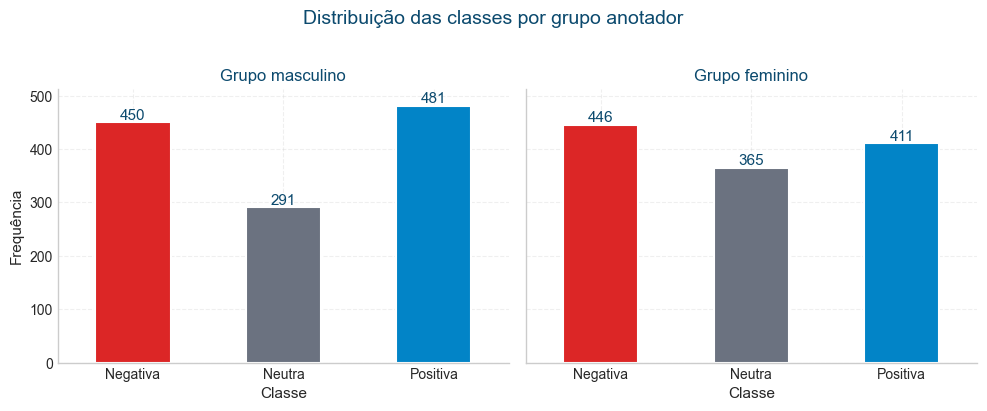

In [12]:
# Visualização: Distribuição de classes (Estilo Nature)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# Cores semânticas para classes de sentimento
cores_classes = [COR_NEGATIVA, COR_NEUTRA, COR_POSITIVA]

for idx, grupo in enumerate(['masculino', 'feminino']):
    col = f'classificacao_majoritaria_{grupo}'
    dist = df[col].value_counts().sort_index()
    
    ax = axes[idx]
    bars = dist.plot(kind='bar', ax=ax, color=cores_classes, edgecolor='white', linewidth=1.5)
    ax.set_title(f'Grupo {grupo}', fontsize=12, fontweight='regular', color=NATURE_BLUE)
    ax.set_xlabel('Classe', fontsize=11)
    ax.set_ylabel('Frequência', fontsize=11)
    ax.set_xticklabels(['Negativa', 'Neutra', 'Positiva'], rotation=0)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    
    for container in ax.containers:
        ax.bar_label(container, fontsize=11, fontweight='regular', color=NATURE_BLUE)
    
    ax.set_ylim(0, dist.max() * 1.15)

plt.suptitle('Distribuição das classes por grupo anotador', fontsize=14, fontweight='regular', color=NATURE_BLUE, y=1.02)
plt.tight_layout()
plt.savefig(GRAFICOS_DIR / 'empi-distribuicao-classes.png', dpi=300, bbox_inches='tight')
plt.show()

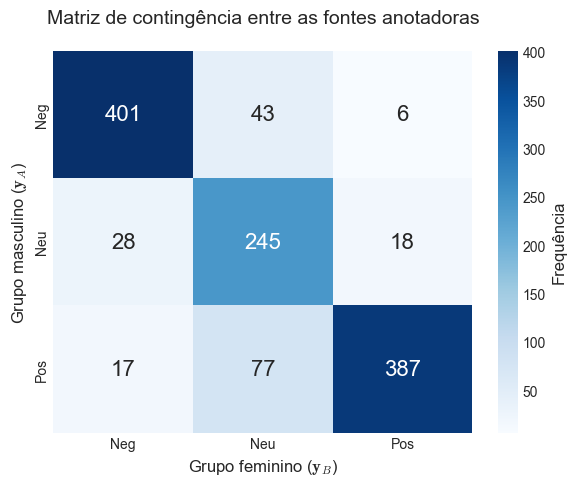

In [13]:
# Matriz de contingência - Baseline
cm = confusion_matrix(y_masculino, y_feminino, labels=[-1, 0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Neg', 'Neu', 'Pos'],
            yticklabels=['Neg', 'Neu', 'Pos'],
            ax=ax, cbar_kws={'label': 'Frequência'},
            annot_kws={'fontsize': 16})

ax.set_title('Matriz de contingência entre as fontes anotadoras', 
             fontsize=14, fontweight='regular', pad=20)
#ax.set_xlabel('Anotações Femininas', fontsize=12)
#ax.set_ylabel('Anotações Masculinas', fontsize=12)
ax.set_xlabel(r'Grupo feminino ($\mathbf{y}_B$)'); ax.set_ylabel(r'Grupo masculino ($\mathbf{y}_A$)')

plt.tight_layout()
plt.savefig(GRAFICOS_DIR / 'empi-matriz-contingencia-baseline.png', dpi=300, bbox_inches='tight')
plt.show()

## Módulo II. Concordância entre modelos

Quatro classificadores supervisionados (SVM, Naive Bayes, Random Forest e Regressão Logística) são treinados separadamente com os rótulos de cada grupo, utilizando a mesma representação textual e as mesmas partições de validação.

Adota-se validação cruzada estratificada em cinco folds, com semente 42 e estratificação pelos rótulos masculinos. O TF-IDF é ajustado exclusivamente sobre os dados de treinamento de cada fold, evitando incorporar informações dos textos de teste à construção do vocabulário.

A concordância entre as predições pareadas é estimada pelo κ de Cohen, calculado em cada fold e posteriormente agregado pela média.

In [14]:
# Preparar validação cruzada e parâmetros do TF-IDF
# O vetorizador é instanciado dentro do loop — fit só nos dados de treino de cada fold.
print("="*80)
print("MÓDULO II: TREINAMENTO PAREADO")
print("="*80)

stopwords_pt = [
    'a', 'o', 'e', 'é', 'de', 'da', 'do', 'em', 'um', 'uma', 'os', 'as', 'dos', 'das',
    'ao', 'à', 'às', 'no', 'na', 'nos', 'nas', 'por', 'para', 'com', 'sem', 'sob', 'sobre',
    'que', 'se', 'me', 'te', 'lhe', 'como', 'mas', 'ou', 'quando', 'onde', 'qual', 'quais',
    'ele', 'ela', 'eles', 'elas', 'eu', 'tu', 'nós', 'vós', 'você', 'vocês',
    'meu', 'minha', 'meus', 'minhas', 'seu', 'sua', 'seus', 'suas', 'nosso', 'nossa',
    'este', 'esta', 'esse', 'essa', 'aquele', 'aquela', 'isto', 'isso', 'aquilo',
    'foi', 'ser', 'ter', 'estar', 'fazer', 'ir', 'ver', 'dar', 'saber',
    'há', 'muito', 'mais', 'menos', 'bem', 'mal', 'já', 'ainda', 'só', 'também',
    'até', 'depois', 'antes', 'agora', 'então', 'aqui', 'ali', 'lá',
    'sim', 'não', 'nem', 'nunca', 'sempre', 'nada', 'tudo', 'todo', 'algum', 'nenhum'
]

tfidf_params = dict(
    max_features=10000,
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.90,
    strip_accents=None,
    stop_words=stopwords_pt,
    sublinear_tf=True,
    use_idf=True,
    norm='l2'
)

frases = df['frase'].values

print(f"[OK] TF-IDF será ajustado por fold (fit no treino, transform no teste)")
print(f"[OK] Parâmetros: ngram=(1,3), max=10000, min_df=3, max_df=0.90, sublinear, norm=l2")


MÓDULO II: TREINAMENTO PAREADO
[OK] TF-IDF será ajustado por fold (fit no treino, transform no teste)
[OK] Parâmetros: ngram=(1,3), max=10000, min_df=3, max_df=0.90, sublinear, norm=l2


In [15]:
# Treinamento pareado com TF-IDF por fold
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

resultados_modelos = []
predicoes_totais = []

print(f"[OK] StratifiedKFold: {N_FOLDS} folds")
print("\nIniciando treinamento pareado...\n")

inicio_treino = datetime.now()

for nome_modelo, modelo_template in modelos.items():
    print(f"  >>> {nome_modelo}")
    print(f"      " + "-"*40)

    metricas_folds = []

    for fold, (train_idx, test_idx) in enumerate(skf.split(frases, y_masculino), 1):

        # TF-IDF: fit APENAS nos dados de treino deste fold.
        # Ambos os modelos do par usam o mesmo vetorizador (ajustado em X_train),
        # preservando comparabilidade pareada sem expor dados de teste ao fit.
        vectorizer = TfidfVectorizer(**tfidf_params)
        X_train = vectorizer.fit_transform(frases[train_idx])
        X_test  = vectorizer.transform(frases[test_idx])

        y_masc_train = y_masculino.iloc[train_idx]
        y_masc_test  = y_masculino.iloc[test_idx]
        y_fem_train  = y_feminino.iloc[train_idx]
        y_fem_test   = y_feminino.iloc[test_idx]

        # Treinar modelo masculino
        modelo_masc = clone(modelo_template)
        modelo_masc.fit(X_train, y_masc_train)
        pred_masc = modelo_masc.predict(X_test)

        # Treinar modelo feminino
        modelo_fem = clone(modelo_template)
        modelo_fem.fit(X_train, y_fem_train)
        pred_fem = modelo_fem.predict(X_test)

        # Métricas
        kappa_inter        = cohen_kappa_score(pred_masc, pred_fem)
        concordancia_inter = np.mean(pred_masc == pred_fem)

        acc_masc = accuracy_score(y_masc_test, pred_masc)
        acc_fem  = accuracy_score(y_fem_test, pred_fem)

        prec_masc, rec_masc, f1_masc, _ = precision_recall_fscore_support(
            y_masc_test, pred_masc, average='weighted', zero_division=0
        )
        prec_fem, rec_fem, f1_fem, _ = precision_recall_fscore_support(
            y_fem_test, pred_fem, average='weighted', zero_division=0
        )

        metricas_folds.append({
            'modelo':                     nome_modelo,
            'fold':                       fold,
            'kappa_inter_modelos':        kappa_inter,
            'concordancia_inter_modelos': concordancia_inter,
            'acc_masculino':              acc_masc,
            'acc_feminino':               acc_fem,
            'precision_masculino':        prec_masc,
            'precision_feminino':         prec_fem,
            'recall_masculino':           rec_masc,
            'recall_feminino':            rec_fem,
            'f1_masculino':               f1_masc,
            'f1_feminino':                f1_fem
        })

        # Armazenar predições
        for i, idx in enumerate(test_idx):
            predicoes_totais.append({
                'modelo':            nome_modelo,
                'fold':              fold,
                'frase_id':          int(idx),
                'frase':             df.iloc[idx]['frase'][:100],
                'real_masculino':    int(y_masc_test.iloc[i]),
                'real_feminino':     int(y_fem_test.iloc[i]),
                'pred_masculino':    int(pred_masc[i]),
                'pred_feminino':     int(pred_fem[i]),
                'concordancia_real': int(y_masc_test.iloc[i] == y_fem_test.iloc[i]),
                'concordancia_pred': int(pred_masc[i] == pred_fem[i])
            })

        print(f"      Fold {fold}: κ={kappa_inter:.4f}, Acc_M={acc_masc:.4f}, Acc_F={acc_fem:.4f}")

    # Agregar resultados do modelo
    df_folds = pd.DataFrame(metricas_folds)

    metricas_agregadas = {
        'modelo':             nome_modelo,
        'kappa_mean':         df_folds['kappa_inter_modelos'].mean(),
        'kappa_std':          df_folds['kappa_inter_modelos'].std(),
        'concordancia_mean':  df_folds['concordancia_inter_modelos'].mean(),
        'concordancia_std':   df_folds['concordancia_inter_modelos'].std(),
        'acc_masculino_mean': df_folds['acc_masculino'].mean(),
        'acc_masculino_std':  df_folds['acc_masculino'].std(),
        'acc_feminino_mean':  df_folds['acc_feminino'].mean(),
        'acc_feminino_std':   df_folds['acc_feminino'].std(),
        'f1_masculino_mean':  df_folds['f1_masculino'].mean(),
        'f1_feminino_mean':   df_folds['f1_feminino'].mean()
    }

    resultados_modelos.append(metricas_agregadas)

    print(f"      [OK] kappa_medio = {metricas_agregadas['kappa_mean']:.4f} +/- {metricas_agregadas['kappa_std']:.4f}\n")

duracao = datetime.now() - inicio_treino
print(f"[OK] Treinamento concluído em {duracao}")

[OK] StratifiedKFold: 5 folds

Iniciando treinamento pareado...

  >>> SVM
      ----------------------------------------
      Fold 1: κ=0.5414, Acc_M=0.3633, Acc_F=0.2980
      Fold 2: κ=0.3862, Acc_M=0.3918, Acc_F=0.3510
      Fold 3: κ=0.5310, Acc_M=0.3320, Acc_F=0.3648
      Fold 4: κ=0.4713, Acc_M=0.3811, Acc_F=0.3402
      Fold 5: κ=0.4582, Acc_M=0.3648, Acc_F=0.3648
      [OK] kappa_medio = 0.4776 +/- 0.0626

  >>> NB
      ----------------------------------------
      Fold 1: κ=0.5581, Acc_M=0.3592, Acc_F=0.3143
      Fold 2: κ=0.3270, Acc_M=0.3673, Acc_F=0.3429
      Fold 3: κ=0.4901, Acc_M=0.3320, Acc_F=0.3320
      Fold 4: κ=0.5021, Acc_M=0.3934, Acc_F=0.3770
      Fold 5: κ=0.4626, Acc_M=0.3975, Acc_F=0.3852
      [OK] kappa_medio = 0.4680 +/- 0.0861

  >>> RF
      ----------------------------------------
      Fold 1: κ=0.5460, Acc_M=0.3592, Acc_F=0.3143
      Fold 2: κ=0.3948, Acc_M=0.3959, Acc_F=0.3469
      Fold 3: κ=0.4852, Acc_M=0.3156, Acc_F=0.3566
      Fold 4: κ

In [16]:
# Criar DataFrames de resultados
df_metricas_modelos = pd.DataFrame(resultados_modelos)
df_predicoes = pd.DataFrame(predicoes_totais)

print(f"\n[OK] Métricas: {df_metricas_modelos.shape}")
print(f"[OK] Predições: {df_predicoes.shape}")

df_metricas_modelos


[OK] Métricas: (4, 11)
[OK] Predições: (4888, 10)


,modelo,kappa_mean,kappa_std,concordancia_mean,concordancia_std,acc_masculino_mean,acc_masculino_std,acc_feminino_mean,acc_feminino_std,f1_masculino_mean,f1_feminino_mean
0,SVM,0.4776,0.0626,0.6719,0.0405,0.3666,0.0227,0.3437,0.0276,0.3390,0.3395
1,NB,0.4680,0.0861,0.6702,0.0604,0.3699,0.0268,0.3503,0.0301,0.3275,0.3394
2,RF,0.5019,0.0650,0.6899,0.0406,0.3674,0.0322,0.3355,0.0194,0.3423,0.3325
3,LR,0.5140,0.0618,0.6899,0.0444,0.3593,0.0340,0.3486,0.0292,0.3350,0.3451


In [17]:
# Salvar resultados
df_metricas_modelos.to_csv(RESULTS_DIR / "metricas-modelos-pareados.csv", index=False)
df_predicoes.to_csv(RESULTS_DIR / "predicoes-completas.csv", index=False)

print("\n[OK] Arquivos salvos:")
print("  - metricas-modelos-pareados.csv")
print("  - predicoes-completas.csv")


[OK] Arquivos salvos:
  - metricas-modelos-pareados.csv
  - predicoes-completas.csv


### Análise de sensibilidade dos estimadores

Comparam-se o κ médio dos cinco folds e o κ das predições reunidas, além dos respectivos procedimentos bootstrap. Esta análise registra a estabilidade das estimativas sem modificar os resultados de treinamento.


In [18]:
# Comparação entre κ médio dos folds e κ das predições reunidas
import pandas as pd
from sklearn.metrics import cohen_kappa_score

metricas = df_metricas_modelos
predicoes = df_predicoes

comparacao = []

for modelo, grupo in predicoes.groupby("modelo"):
    # Estimador principal: média dos cinco folds
    kappa_folds = metricas.loc[
        metricas["modelo"] == modelo, "kappa_mean"
    ].iloc[0]

    # Estimador alternativo: predições out-of-fold reunidas
    kappa_global = cohen_kappa_score(
        grupo["pred_masculino"],
        grupo["pred_feminino"]
    )

    comparacao.append({
        "modelo": modelo,
        "kappa_medio_folds": kappa_folds,
        "kappa_global": kappa_global,
        "diferenca": kappa_global - kappa_folds,
        "n_predicoes": len(grupo)
    })

df_comparacao = pd.DataFrame(comparacao)

display(
    df_comparacao.round(4).sort_values("modelo")
)

,modelo,kappa_medio_folds,kappa_global,diferenca,n_predicoes
0,LR,0.5140,0.5133,-0.0007,1222
1,NB,0.4680,0.4665,-0.0015,1222
2,RF,0.5019,0.5034,0.0014,1222
3,SVM,0.4776,0.4792,0.0016,1222


In [19]:
# Comparação dos procedimentos de bootstrap para Δκ
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score

N_BOOT = 10000
resultados_comparacao = []

for modelo, dados in df_predicoes.groupby("modelo"):
    folds = [
        grupo.reset_index(drop=True)
        for _, grupo in dados.groupby("fold")
    ]

    rng_global = np.random.default_rng(SEED)
    rng_folds = np.random.default_rng(SEED)

    delta_global = np.empty(N_BOOT)
    delta_folds = np.empty(N_BOOT)

    for b in range(N_BOOT):

        # Método original: todas as predições reunidas
        idx = rng_global.integers(0, len(dados), len(dados))
        amostra = dados.iloc[idx]

        k_global = cohen_kappa_score(
            amostra["pred_masculino"],
            amostra["pred_feminino"]
        )
        delta_global[b] = kappa_anot - k_global

        # Método revisado: reamostragem dentro de cada fold
        kappas = []

        for fold in folds:
            idx = rng_folds.integers(0, len(fold), len(fold))
            amostra_fold = fold.iloc[idx]

            k = cohen_kappa_score(
                amostra_fold["pred_masculino"],
                amostra_fold["pred_feminino"]
            )
            kappas.append(k)

        delta_folds[b] = kappa_anot - np.mean(kappas)

    for metodo, valores in [
        ("Original", delta_global),
        ("Revisado", delta_folds)
    ]:
        validos = valores[np.isfinite(valores)]

        if len(validos) != N_BOOT:
            raise ValueError(
                f"{modelo}: bootstrap {metodo} produziu "
                f"{N_BOOT - len(validos)} estimativas inválidas."
            )

        li, ls = np.percentile(validos, [2.5, 97.5])

        direcao = (
            "Amplifica" if li > 0
            else "Converge" if ls < 0
            else "Inconclusivo"
        )

        resultados_comparacao.append({
            "modelo": modelo,
            "metodo": metodo,
            "delta_medio_boot": validos.mean(),
            "ic_inferior": li,
            "ic_superior": ls,
            "direcao": direcao
        })

df_comparacao_bootstrap = pd.DataFrame(resultados_comparacao)

display(
    df_comparacao_bootstrap
    .sort_values(["modelo", "metodo"])
    .round(4)
)
# Preservar a comparação na pasta da revisão.
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_comparacao_bootstrap.to_csv(RESULTS_DIR / "comparacao-bootstrap.csv", index=False)


,modelo,metodo,delta_medio_boot,ic_inferior,ic_superior,direcao
0,LR,Original,0.2528,0.2159,0.2899,Amplifica
1,LR,Revisado,0.2531,0.2160,0.2897,Amplifica
2,NB,Original,0.2997,0.2626,0.3365,Amplifica
3,NB,Revisado,0.2990,0.2625,0.3352,Amplifica
4,RF,Original,0.2633,0.2232,0.3027,Amplifica
5,RF,Revisado,0.2653,0.2266,0.3036,Amplifica
6,SVM,Original,0.2874,0.2491,0.3258,Amplifica
7,SVM,Revisado,0.2894,0.2510,0.3279,Amplifica


### Análise complementar das predições

A concordância entre as predições é complementada pelo teste qui-quadrado e pelo V de Cramér, permitindo examinar a associação entre as classificações produzidas por cada par de modelos.

As matrizes de contingência e os gráficos oferecem uma representação das diferenças observadas, sem substituir o κ de Cohen como medida central de concordância.

In [20]:
# Análise estatística das predições
print("="*80)
print("MÓDULO III: DIVERGÊNCIA")
print("="*80)

analises = []

for modelo in modelos.keys():
    pred_modelo = df_predicoes[df_predicoes['modelo'] == modelo]
    
    contingency = pd.crosstab(pred_modelo['pred_masculino'], pred_modelo['pred_feminino'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    
    n = len(pred_modelo)
    min_dim = min(contingency.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0.0
    
    kappa_mean = df_metricas_modelos[df_metricas_modelos['modelo'] == modelo]['kappa_mean'].values[0]
    
    analises.append({
        'modelo': modelo,
        'kappa_pred': kappa_mean,
        'chi2': chi2,
        'p_value': p_value,
        'cramers_v': cramers_v,
        'n_predicoes': n
    })
    
    print(f"\n  {modelo}:")
    print(f"    κ_pred = {kappa_mean:.4f}")
    print(f"    χ² = {chi2:.2f} (p < {p_value:.2e})")
    print(f"    Cramér's V = {cramers_v:.4f}")

df_analises = pd.DataFrame(analises)
df_analises

MÓDULO III: DIVERGÊNCIA

  SVM:
    κ_pred = 0.4776
    χ² = 573.08 (p < 1.04e-122)
    Cramér's V = 0.4842

  NB:
    κ_pred = 0.4680
    χ² = 559.49 (p < 9.04e-120)
    Cramér's V = 0.4785

  RF:
    κ_pred = 0.5019
    χ² = 630.99 (p < 3.04e-135)
    Cramér's V = 0.5081

  LR:
    κ_pred = 0.5140
    χ² = 660.48 (p < 1.25e-141)
    Cramér's V = 0.5199


,modelo,kappa_pred,chi2,p_value,cramers_v,n_predicoes
0,SVM,0.4776,573.0774,0.0000,0.4842,1222
1,NB,0.4680,559.4911,0.0000,0.4785,1222
2,RF,0.5019,630.9911,0.0000,0.5081,1222
3,LR,0.5140,660.4816,0.0000,0.5199,1222


In [21]:
import matplotlib.pyplot as plt

FONTE = "DejaVu Sans"
plt.rcParams.update({
    "mathtext.fontset": "custom",
    "mathtext.rm": FONTE,
    "mathtext.it": f"{FONTE}:italic",
    "mathtext.bf": f"{FONTE}:bold",
})

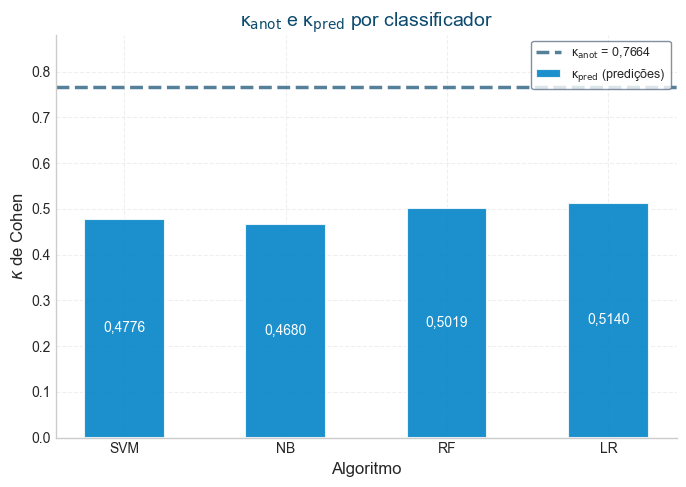

In [22]:
# Visualizar κ_anot vs κ_pred
fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(df_analises))
width = 0.5

bars = ax.bar(x, df_analises['kappa_pred'], width,
              #label='κ_pred (Predições)', color=NATURE_BLUE_MED, alpha=0.9,
              label=K_PRED + ' (predições)', color=NATURE_BLUE_MED, alpha=0.9,
              edgecolor='white', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height * 0.5,
            f'{height:.4f}'.replace(".", ","), ha='center', va='center', fontsize=10, 
            fontweight='regular', color='white')

ax.axhline(y=kappa_anot, color=NATURE_BLUE, linestyle='--', alpha=0.7, linewidth=2.5,
           #label=f'κ_anot (Anotadores) = {kappa_anot:.4f}')
           #label=f'{K_ANOT} = {vir(kappa_anot)}')
           label=f'{K_ANOT} = {f"{kappa_anot:.4f}".replace(".", ",")}')
ax.set_xlabel('Algoritmo', fontsize=12, fontweight='regular')
ax.set_ylabel(r"$\kappa$ de Cohen", fontsize=12, fontweight='regular')
ax.set_title(f'{K_ANOT} e {K_PRED} por classificador', fontsize=14, fontweight='regular', color=NATURE_BLUE)
ax.set_xticks(x)
ax.set_xticklabels(df_analises['modelo'])
ax.legend(frameon=True, facecolor='white', edgecolor=NATURE_GRAY, fontsize=9, loc='upper right')
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, max(kappa_anot, df_analises['kappa_pred'].max()) * 1.15)

plt.tight_layout()
plt.savefig(GRAFICOS_DIR / 'empi-comparacao-kappas.png', dpi=300, bbox_inches='tight')
plt.show()

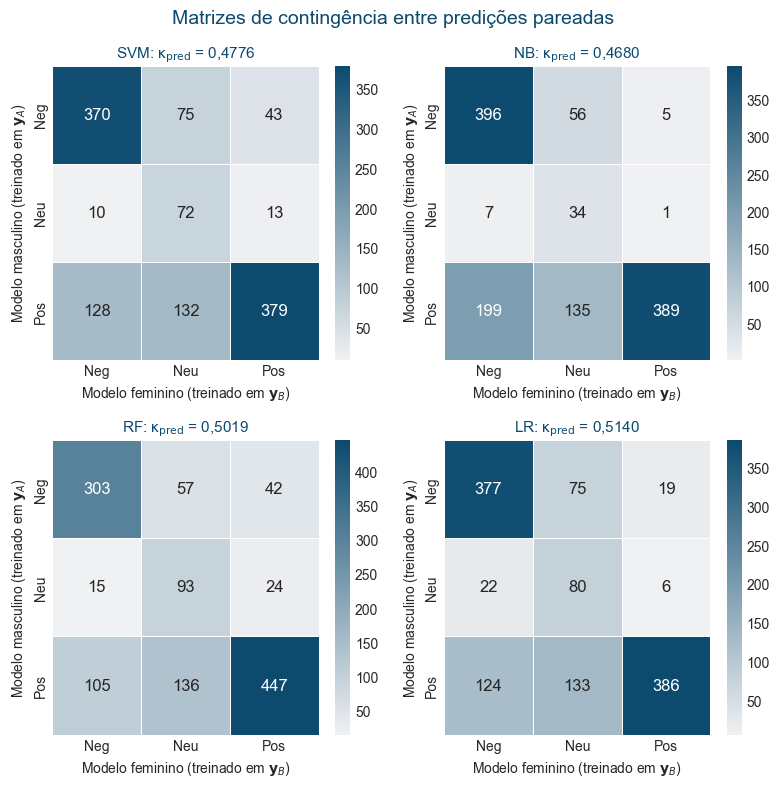

In [23]:
# Matrizes de confusão dos modelos
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

# Cmap azul acadêmico
cmap_nature = sns.light_palette(NATURE_BLUE, as_cmap=True)

for idx, modelo in enumerate(modelos.keys()):
    pred_modelo = df_predicoes[df_predicoes['modelo'] == modelo]
    
    cm = confusion_matrix(pred_modelo['pred_masculino'], pred_modelo['pred_feminino'],
                         labels=[-1, 0, 1])
    
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_nature,
                xticklabels=['Neg', 'Neu', 'Pos'], 
                yticklabels=['Neg', 'Neu', 'Pos'],
                ax=ax, #cbar_kws={'label': 'Frequência'},
                annot_kws={'fontsize': 12, 'fontweight': 'regular'},
                linewidths=0.5, linecolor='white')
    
    kappa = df_metricas_modelos[df_metricas_modelos['modelo'] == modelo]['kappa_mean'].values[0]
    
    #ax.set_title(f'{modelo} - κ = {kappa:.4f}', fontsize=11, fontweight='regular', color=NATURE_BLUE)
    ax.set_title(f'{modelo}: {K_PRED} = {vir(kappa)}', fontsize=11, fontweight='regular', color=NATURE_BLUE)
    ax.set_xlabel(r'Modelo feminino (treinado em $\mathbf{y}_B$)', fontsize=10, fontweight='regular')
    ax.set_ylabel(r'Modelo masculino (treinado em $\mathbf{y}_A$)', fontsize=10, fontweight='regular')
    plt.suptitle('Matrizes de contingência entre predições pareadas', fontsize=10)

#plt.suptitle('Matrizes de Contigência - Análise Pareada', fontsize=14, fontweight='regular', color=NATURE_BLUE)
plt.suptitle('Matrizes de contingência entre predições pareadas', fontsize=14, fontweight='regular', color=NATURE_BLUE)

plt.tight_layout()
plt.savefig(GRAFICOS_DIR / 'matrizes-confusao-modelos.png', dpi=300, bbox_inches='tight')
plt.show()

## Módulo III. Amplificação das divergências

A amplificação é quantificada pela diferença entre a concordância inicial dos anotadores e a concordância média das predições de cada classificador:

\[
\Delta\kappa = \kappa_{\mathrm{anot}} - \kappa_{\mathrm{pred}}
\]

Valores positivos de Δκ indicam redução da concordância após o aprendizado supervisionado, caracterizando amplificação das divergências anotativas.

Complementarmente, a severidade é classificada pelo número de faixas de concordância perdidas, segundo a categorização de Landis e Koch (1977). No código atual, a variável de detecção de amplificação considera especificamente a ocorrência dessa mudança de faixa.

**Referência:** Landis, J. R.; Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics*, 33(1), 159–174.

In [24]:
# Calcular Δκ (Delta Kappa) com critério Landis & Koch (1977)
print("=" * 80)
print("MÓDULO IV: DETECÇÃO DE AMPLIFICAÇÃO (Critério: Landis & Koch, 1977)")
print("=" * 80)

# Faixas de concordância Kappa segundo Landis & Koch (1977)
LK_BANDS = [
    ('Poor', -1.0, 0.0),
    ('Slight', 0.0, 0.20),
    ('Fair', 0.20, 0.40),
    ('Moderate', 0.40, 0.60),
    ('Substantial', 0.60, 0.80),
    ('Almost Perfect', 0.80, 1.00),
]

LK_RANK = {name: i for i, (name, _, _) in enumerate(LK_BANDS)}


def obter_faixa_landis_koch(kappa):
    """Retorna a faixa de concordância segundo Landis & Koch (1977)."""
    if pd.isna(kappa):
        return np.nan
    for name, low, high in LK_BANDS:
        if kappa <= high:
            return name
    return 'Almost Perfect'


def classificar_severidade_por_queda_de_faixas(kappa_anot, kappa_pred):
    """Classifica severidade pela queda de faixas de concordância (Landis & Koch, 1977)."""
    faixa_inicial = obter_faixa_landis_koch(kappa_anot)
    faixa_modelo = obter_faixa_landis_koch(kappa_pred)

    faixas_perdidas = max(0, LK_RANK.get(faixa_inicial, 0) - LK_RANK.get(faixa_modelo, 0))

    SEVERIDADE = {0: "Nulo", 1: "Restrito", 2: "Amplo"}
    severidade = SEVERIDADE.get(faixas_perdidas, "Acentuado")

    return severidade, faixas_perdidas, faixa_inicial, faixa_modelo


divergencias = []

for _, row in df_metricas_modelos.iterrows():
    delta_kappa = kappa_anot - row['kappa_mean']
    severidade, faixas_perdidas, faixa_inicial, faixa_modelo = classificar_severidade_por_queda_de_faixas(
        kappa_anot, row['kappa_mean']
    )

    divergencias.append({
        'modelo': row['modelo'],
        'kappa_anot': kappa_anot,
        'kappa_pred': row['kappa_mean'],
        'delta_kappa': delta_kappa,
        'faixa_inicial_lk': faixa_inicial,
        'faixa_modelo_lk': faixa_modelo,
        'faixas_perdidas': faixas_perdidas,
        'severidade': severidade,
        'amplificacao_detectada': delta_kappa > 0
    })

    print(f"\n  {row['modelo']}:")
    print(f"    κ_anot = {kappa_anot:.4f} ({faixa_inicial})")
    print(f"    κ_pred = {row['kappa_mean']:.4f} ({faixa_modelo})")
    print(f"    Δκ = {delta_kappa:+.4f}")
    print(f"    Faixas perdidas: {faixas_perdidas}")
    print(f"    Severidade: {severidade}")

df_divergencia = pd.DataFrame(divergencias)
df_divergencia


MÓDULO IV: DETECÇÃO DE AMPLIFICAÇÃO (Critério: Landis & Koch, 1977)

  SVM:
    κ_anot = 0.7664 (Substantial)
    κ_pred = 0.4776 (Moderate)
    Δκ = +0.2888
    Faixas perdidas: 1
    Severidade: Restrito

  NB:
    κ_anot = 0.7664 (Substantial)
    κ_pred = 0.4680 (Moderate)
    Δκ = +0.2984
    Faixas perdidas: 1
    Severidade: Restrito

  RF:
    κ_anot = 0.7664 (Substantial)
    κ_pred = 0.5019 (Moderate)
    Δκ = +0.2645
    Faixas perdidas: 1
    Severidade: Restrito

  LR:
    κ_anot = 0.7664 (Substantial)
    κ_pred = 0.5140 (Moderate)
    Δκ = +0.2524
    Faixas perdidas: 1
    Severidade: Restrito


,modelo,kappa_anot,kappa_pred,delta_kappa,faixa_inicial_lk,faixa_modelo_lk,faixas_perdidas,severidade,amplificacao_detectada
0,SVM,0.7664,0.4776,0.2888,Substantial,Moderate,1,Restrito,True
1,NB,0.7664,0.4680,0.2984,Substantial,Moderate,1,Restrito,True
2,RF,0.7664,0.5019,0.2645,Substantial,Moderate,1,Restrito,True
3,LR,0.7664,0.5140,0.2524,Substantial,Moderate,1,Restrito,True


In [25]:
# Salvar divergências
df_divergencia.to_csv(RESULTS_DIR / "divergencia-amplificacao.csv", index=False)
print("\n[OK] Salvo: divergencia-amplificacao.csv")


[OK] Salvo: divergencia-amplificacao.csv


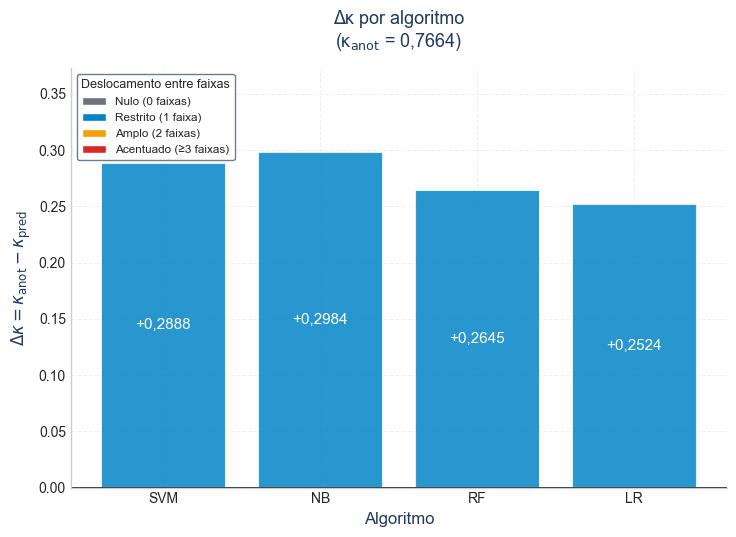

In [26]:
# Visualizar Δκ com cores por severidade (critério Landis & Koch)
fig, ax = plt.subplots(figsize=(7.5, 5.5))

SEV_COLORS = {
    'Nulo': '#6B7280',
    'Restrito': '#0284C7',
    'Amplo': '#F59E0B',
    'Acentuado': '#DC2626'
}

cores = [SEV_COLORS.get(sev, '#6B7280') for sev in df_divergencia['severidade']]

bars = ax.bar(df_divergencia['modelo'], df_divergencia['delta_kappa'],
              color=cores, alpha=0.85, edgecolor='white', linewidth=1.5)

ax.axhline(y=0, color='black', linestyle='-', linewidth=1.2)

ax.set_xlabel('Algoritmo', fontsize=12, fontweight='regular', color=NATURE_ACCENT)
#ax.set_ylabel('Δκ (κ_anot - κ_pred)', fontsize=12, fontweight='regular', color=NATURE_ACCENT)

ax.set_ylabel(r'$\Delta\kappa = \kappa_{\mathrm{anot}} - \kappa_{\mathrm{pred}}$', fontsize=12, fontweight='regular', color=NATURE_ACCENT)

#ax.set_title('Δκ por Algoritmo\n(Kappa inicial = {:.4f})'.format(kappa_anot),
#             fontsize=13, fontweight='regular', color=NATURE_ACCENT, pad=15)


ax.set_title(f'{DK} por algoritmo\n({K_ANOT} = {vir(kappa_anot)})',
             fontsize=13, fontweight='regular', color=NATURE_ACCENT, pad=15)


ax.grid(axis='y', alpha=0.3)

max_delta = df_divergencia['delta_kappa'].max()
margin = abs(max_delta) * 0.25
ax.set_ylim(0, max(max_delta + margin, 0.20))

for bar in bars:
    height = bar.get_height()
    if abs(height) > 0.03:
        ax.text(bar.get_x() + bar.get_width()/2., height / 2,
                f'{height:+.4f}'.replace(".", ","), ha='center', va='center',
                fontsize=11, fontweight='regular', color='white')
    else:
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.015,
                f'{height:+.4f}'.replace(".", ","), ha='center', va='bottom',
                fontsize=11, fontweight='regular', color='black')

legend_elements = [
    Patch(facecolor=SEV_COLORS['Nulo'], edgecolor='white', label='Nulo (0 faixas)'),
    Patch(facecolor=SEV_COLORS['Restrito'], edgecolor='white', label='Restrito (1 faixa)'),
    Patch(facecolor=SEV_COLORS['Amplo'], edgecolor='white', label='Amplo (2 faixas)'),
    Patch(facecolor=SEV_COLORS['Acentuado'], edgecolor='white', label='Acentuado (≥3 faixas)')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=8.5,
          title='Deslocamento entre faixas', title_fontsize=9,
          frameon=True, facecolor='white', edgecolor=NATURE_GRAY,
          framealpha=0.95, shadow=False)

plt.tight_layout()
plt.savefig(GRAFICOS_DIR / 'empi-amplificacao-delta-kappa.png', dpi=300, bbox_inches='tight')
plt.show()


### Incerteza da amplificação

O bootstrap compara a reamostragem das predições concatenadas com a reamostragem por fold, seguida da média dos cinco valores de κ. A segunda abordagem corresponde ao estimador principal adotado para Δκ e fornece o intervalo utilizado na conclusão inferencial.

São realizadas 10.000 reamostragens com IC percentílico de 95%. O κ inicial é mantido fixo, e os intervalos estão condicionados às predições e partições observadas, sem abranger novos treinamentos.


In [27]:
# Intervalo revisado: bootstrap por fold, previamente calculado na análise de sensibilidade.
print("\nIC95% de Δκ: estimador médio dos cinco folds\n")

revisado = df_comparacao_bootstrap.loc[
    df_comparacao_bootstrap["metodo"] == "Revisado"
].copy()

resultados_bootstrap = []
for _, r in revisado.iterrows():
    modelo = r["modelo"]
    li, ls = float(r["ic_inferior"]), float(r["ic_superior"])
    direcao = "AMPLIFICA" if li > 0 else "REDUZ" if ls < 0 else "INCONCLUSIVO"
    delta_observado = float(df_divergencia.loc[
        df_divergencia["modelo"] == modelo, "delta_kappa"
    ].iloc[0])
    resultados_bootstrap.append({
        "modelo": modelo,
        "delta_kappa": delta_observado,
        "delta_bootstrap_mean": float(r["delta_medio_boot"]),
        "ic_95_lower": li,
        "ic_95_upper": ls,
        "significativo": bool(li > 0 or ls < 0),
        "direcao": direcao
    })
    print(f"{modelo}: Δκ={delta_observado:+.4f}, IC95%=[{li:+.4f}, {ls:+.4f}] ({direcao})")

df_bootstrap = pd.DataFrame(resultados_bootstrap)
df_bootstrap.to_csv(RESULTS_DIR / "significancia-delta-kappa.csv", index=False)
print("[OK] Salvo: significancia-delta-kappa.csv")



IC95% de Δκ: estimador médio dos cinco folds

LR: Δκ=+0.2524, IC95%=[+0.2160, +0.2897] (AMPLIFICA)
NB: Δκ=+0.2984, IC95%=[+0.2625, +0.3352] (AMPLIFICA)
RF: Δκ=+0.2645, IC95%=[+0.2266, +0.3036] (AMPLIFICA)
SVM: Δκ=+0.2888, IC95%=[+0.2510, +0.3279] (AMPLIFICA)
[OK] Salvo: significancia-delta-kappa.csv


In [28]:
# Gerar relatório textual
output_file = RESULTS_DIR / "relatorio-amplificacao-vies.txt"

BASELINE_FORMATS = {
    'Cohen_Kappa': '.4f', 'Concordancia': '.4f', 'Cramers_V': '.4f',
    'Kappa_IC95_Lower': '.4f', 'Kappa_IC95_Upper': '.4f',
    'Chi2': '.2f', 'p_value': '.2e', 'N_amostras': '.0f'
}

with open(output_file, 'w', encoding='utf-8') as f:
    f.write("=" * 80 + "\n")
    f.write("RELATÓRIO DE AMPLIFICAÇÃO DAS DIVERGÊNCIAS - MADA FASE 2\n")
    f.write("=" * 80 + "\n\n")

    f.write(f"Data: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}\n")
    f.write(f"Seed: {SEED}\n")
    f.write(f"K-Fold: {N_FOLDS}\n")
    f.write(f"N Amostras: {len(df)}\n\n")

    f.write("-" * 80 + "\n")
    f.write("BASELINE\n")
    f.write("-" * 80 + "\n\n")

    for _, row in df_baseline.iterrows():
        fmt = BASELINE_FORMATS.get(row['metrica'], '')
        f.write(f"{row['metrica']:25}: {row['valor']:{fmt}}\n")

    f.write("\n" + "-" * 80 + "\n")
    f.write("AMPLIFICAÇÃO\n")
    f.write("-" * 80 + "\n\n")

    f.write(f"κ_anot: {kappa_anot:.4f}\n\n")

    for _, row in df_divergencia.iterrows():
        f.write(f"{row['modelo']}:\n")
        f.write(f"  κ_pred : {row['kappa_pred']:.4f}\n")
        f.write(f"  Δκ        : {row['delta_kappa']:+.4f}\n")
        f.write(f"  Severidade: {row['severidade']}\n")
        f.write(f"  Amplificação pontual?: {'SIM' if row['amplificacao_detectada'] else 'NÃO'}\n\n")

    f.write("=" * 80 + "\n")

    f.write("\nEVIDÊNCIA INFERENCIAL (IC95% bootstrap por fold)\n")
    for _, r in df_bootstrap.iterrows():
        f.write(f"{r['modelo']}: IC95% [{r['ic_95_lower']:+.4f}; {r['ic_95_upper']:+.4f}], {r['direcao']}\n")
    n_evidencia = int((df_bootstrap['direcao'] == 'AMPLIFICA').sum())
    f.write(f"\n{n_evidencia}/{len(df_bootstrap)} modelos com evidência de amplificação.\n")
    f.write("Nota: os intervalos condicionam-se às predições e ao κ inicial observados.\n")

print(f"\n[OK] Relatório salvo: {output_file}")



[OK] Relatório salvo: dados\03-resultados-empiricos\revisao\relatorio-amplificacao-vies.txt


## Resumo Final

In [29]:
# Interpretação focada em amplificação (Critério: Landis & Koch, 1977)
print("="*80)
print("ANÁLISE ESPECÍFICA: AMPLIFICAÇÃO DE VIÉS (Landis & Koch, 1977)")
print("="*80)

print(f"\n{'MODELO':<10} | {'kappa_anot':^14} | {'kappa_pred':^14} | {'Delta_kappa':^12} | {'Faixas':^8} | {'SEVERIDADE':^15}")
print("-"*95)

for _, row in df_divergencia.iterrows():
    faixas = row['faixas_perdidas']
    severidade = row['severidade']
    
    print(f"{row['modelo']:<10} | {row['kappa_anot']:^14.4f} | "
          f"{row['kappa_pred']:^14.4f} | {row['delta_kappa']:^+12.4f} | "
          f"{faixas:^8} | {severidade:^15}")

print("-"*95)

delta_medio = df_divergencia['delta_kappa'].mean()
faixas_perdidas_media = df_divergencia['faixas_perdidas'].mean()

print(f"\nDelta kappa médio: {delta_medio:+.4f}")
print(f"   κ_anot: {kappa_anot:.4f}")
print(f"   κ_pred (média): {df_divergencia['kappa_pred'].mean():.4f}")
print(f"   Faixas perdidas (média): {faixas_perdidas_media:.2f}")

print("\n" + "="*80)
print("INTERPRETAÇÃO (Baseada em Landis & Koch, 1977):")
print("="*80)

n_amplificados = df_divergencia['amplificacao_detectada'].sum()
n_total = len(df_divergencia)

if n_amplificados > 0:
    print(f"\n[AVISO] AMPLIFICAÇÃO DETECTADA")
    print(f"   {n_amplificados}/{n_total} modelos apresentam Δκ positivo")
    print(f"   Modelos concordam MENOS ({df_divergencia['kappa_pred'].mean():.4f})")
    print(f"   que os anotadores ({kappa_anot:.4f})")
    print(f"\n   Distribuição de severidade:")
    for sev in ['Restrito', 'Amplo', 'Acentuado']:
        count = (df_divergencia['severidade'] == sev).sum()
        if count > 0:
            print(f"   - {sev}: {count} modelo(s)")
    print("\n   Conclusão pontual: redução da concordância preditiva")
else:
    print(f"\n[OK] SEM AMPLIFICAÇÃO (Delta kappa medio = {delta_medio:+.4f})")
    print("   Sem Δκ positivo; isso não comprova preservação estatística.")

print("\n" + "="*80)
print("\nEvidência inferencial por modelo (IC95%):")
print(df_bootstrap[["modelo", "ic_95_lower", "ic_95_upper", "direcao"]].to_string(index=False))


ANÁLISE ESPECÍFICA: AMPLIFICAÇÃO DE VIÉS (Landis & Koch, 1977)

MODELO     |   kappa_anot   |   kappa_pred   | Delta_kappa  |  Faixas  |   SEVERIDADE   
-----------------------------------------------------------------------------------------------
SVM        |     0.7664     |     0.4776     |   +0.2888    |    1     |    Restrito    
NB         |     0.7664     |     0.4680     |   +0.2984    |    1     |    Restrito    
RF         |     0.7664     |     0.5019     |   +0.2645    |    1     |    Restrito    
LR         |     0.7664     |     0.5140     |   +0.2524    |    1     |    Restrito    
-----------------------------------------------------------------------------------------------

Delta kappa médio: +0.2760
   κ_anot: 0.7664
   κ_pred (média): 0.4904
   Faixas perdidas (média): 1.00

INTERPRETAÇÃO (Baseada em Landis & Koch, 1977):

[AVISO] AMPLIFICAÇÃO DETECTADA
   4/4 modelos apresentam Δκ positivo
   Modelos concordam MENOS (0.4904)
   que os anotadores (0.7664)

   Distr

In [30]:
# =============================================================================
# RESUMO FINAL DE ARQUIVOS GERADOS
# =============================================================================

print("=" * 80)
print("FASE 2 — RESUMO DE ARQUIVOS GERADOS")
print("=" * 80)

# Verifica automaticamente quais arquivos foram gerados
for dirpath in [RESULTS_DIR, GRAFICOS_DIR]:
    for f in sorted(dirpath.iterdir()):
        if f.is_file():
            print(f"  [OK] {f.relative_to(DATA_DIR)}")

print(f"\n{'=' * 80}")
print("[OK] FASE 2 CONCLUÍDA COM SUCESSO")
print(f"{'=' * 80}")


FASE 2 — RESUMO DE ARQUIVOS GERADOS
  [OK] 03-resultados-empiricos\revisao\comparacao-bootstrap.csv
  [OK] 03-resultados-empiricos\revisao\divergencia-amplificacao.csv
  [OK] 03-resultados-empiricos\revisao\insights-estatisticos-fase2.md
  [OK] 03-resultados-empiricos\revisao\metricas-consistencia-baseline.csv
  [OK] 03-resultados-empiricos\revisao\metricas-modelos-pareados.csv
  [OK] 03-resultados-empiricos\revisao\predicoes-completas.csv
  [OK] 03-resultados-empiricos\revisao\relatorio-amplificacao-vies.txt
  [OK] 03-resultados-empiricos\revisao\significancia-delta-kappa.csv
  [OK] 03-resultados-empiricos\revisao\graficos-empiricos\empi-amplificacao-delta-kappa.png
  [OK] 03-resultados-empiricos\revisao\graficos-empiricos\empi-comparacao-kappas.png
  [OK] 03-resultados-empiricos\revisao\graficos-empiricos\empi-distribuicao-classes.png
  [OK] 03-resultados-empiricos\revisao\graficos-empiricos\empi-matriz-contingencia-baseline.png
  [OK] 03-resultados-empiricos\revisao\graficos-empiric

In [31]:
# Gerar arquivo Markdown com os principais insights estatísticos da Fase 2
from datetime import datetime
from pathlib import Path
import pandas as pd


# Utiliza RESULTS_DIR definido na célula 8
insights_file = RESULTS_DIR / "insights-estatisticos-fase2.md"

df_baseline_local = globals().get("df_baseline")
if df_baseline_local is None:
    df_baseline_local = pd.read_csv(RESULTS_DIR / "metricas-consistencia-baseline.csv")

df_metricas_modelos_local = globals().get("df_metricas_modelos")
if df_metricas_modelos_local is None:
    df_metricas_modelos_local = pd.read_csv(RESULTS_DIR / "metricas-modelos-pareados.csv")

df_divergencia_local = globals().get("df_divergencia")
if df_divergencia_local is None:
    df_divergencia_local = pd.read_csv(RESULTS_DIR / "divergencia-amplificacao.csv")

df_bootstrap_local = globals().get("df_bootstrap")
if df_bootstrap_local is None:
    bootstrap_path = RESULTS_DIR / "significancia-delta-kappa.csv"
    if bootstrap_path.exists():
        df_bootstrap_local = pd.read_csv(bootstrap_path)

# Extrair métricas do baseline via dict para acesso direto
baseline = df_baseline_local.set_index('metrica')['valor'].to_dict()
kappa_anot = float(baseline['Cohen_Kappa'])

delta_medio = float(df_divergencia_local['delta_kappa'].mean())
kappa_pred_medio = float(df_divergencia_local['kappa_pred'].mean())

melhor_kappa = df_metricas_modelos_local.loc[df_metricas_modelos_local['kappa_mean'].idxmax()]
pior_kappa = df_metricas_modelos_local.loc[df_metricas_modelos_local['kappa_mean'].idxmin()]

maior_delta = df_divergencia_local.loc[df_divergencia_local['delta_kappa'].idxmax()]
menor_delta = df_divergencia_local.loc[df_divergencia_local['delta_kappa'].idxmin()]

dist_severidade = df_divergencia_local['severidade'].value_counts().to_dict()
n_amplificados = int(df_divergencia_local['amplificacao_detectada'].sum())
n_total = int(len(df_divergencia_local))
n_modelos = int(len(df_metricas_modelos_local))

n_significativos = int(df_bootstrap_local['significativo'].sum()) if df_bootstrap_local is not None else 0

linhas = [
    "# Principais Insights Estatísticos — MADA Fase 2",
    "",
    f"**Data de geração:** {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}",
    "",
    "## 1) Baseline entre anotadores",
    f"- **Cohen's Kappa inicial:** `{kappa_anot:.4f}`",
    f"- **IC 95% do Kappa (bootstrap):** `[{baseline['Kappa_IC95_Lower']:.4f}, {baseline['Kappa_IC95_Upper']:.4f}]`",
    f"- **Concordância observada:** `{baseline['Concordancia']:.4f}` ({baseline['Concordancia']*100:.2f}%)",
    f"- **Cramér's V:** `{baseline['Cramers_V']:.4f}`",
    "",
    "> Interpretação: há concordância inicial relativamente alta entre os grupos de anotadores.",
    "",
    "## 2) Concordância entre modelos pareados",
    f"- **Média de κ_pred (4 classificadores):** `{kappa_pred_medio:.4f}`",
    f"- **Melhor κ_pred:** `{melhor_kappa['modelo']}` com `{melhor_kappa['kappa_mean']:.4f}`",
    f"- **Pior κ_pred:** `{pior_kappa['modelo']}` com `{pior_kappa['kappa_mean']:.4f}`",
    "",
    "## 3) Amplificação de divergências (Δκ = κ_anot - κ_pred)",
    f"- **Δκ médio:** `{delta_medio:+.4f}`",
    f"- **Maior amplificação:** `{maior_delta['modelo']}` com `Δκ={maior_delta['delta_kappa']:+.4f}`",
    f"- **Menor amplificação:** `{menor_delta['modelo']}` com `Δκ={menor_delta['delta_kappa']:+.4f}`",
    f"- **Modelos com amplificação detectada:** `{n_amplificados}/{n_total}`",
    "",
    "### Severidade (Landis & Koch, 1977)",
]

for sev in ["Nulo", "Restrito", "Amplo", "Acentuado"]:
    linhas.append(f"- **{sev}:** {dist_severidade.get(sev, 0)} modelo(s)")

linhas += [
    "",
    "## 4) Significância estatística (bootstrap de Δκ)",
    f"- **Modelos com Δκ estatisticamente significativo:** `{n_significativos}/{n_modelos}`",
]

if df_bootstrap_local is not None:
    for _, r in df_bootstrap_local.iterrows():
        linhas.append(
            f"  - {r['modelo']}: Δκ observado `{r['delta_kappa']:+.4f}`, "
            f"IC95% `[{r['ic_95_lower']:+.4f}, {r['ic_95_upper']:+.4f}]`, "
            f"direção: **{r['direcao']}**"
        )

linhas += [
    "",
    "## 5) Conclusão executiva",
    f"- **Amplificação pontual (Δκ > 0):** `{n_amplificados}/{n_total}` classificadores.",
    f"- **Evidência de amplificação (IC95% inteiramente positivo):** `{int((df_bootstrap_local['direcao'] == 'AMPLIFICA').sum()) if df_bootstrap_local is not None else 'não calculada'}` classificadores.",
    "- As faixas de Landis e Koch descrevem deslocamento categórico, não determinam significância estatística.",
    "",
    "---",
    f"Arquivo gerado automaticamente em: `{insights_file}`"
]

with open(insights_file, "w", encoding="utf-8") as f:
    f.write("\n".join(linhas))

print(f"[OK] Arquivo de insights salvo: {insights_file}")


[OK] Arquivo de insights salvo: dados\03-resultados-empiricos\revisao\insights-estatisticos-fase2.md


In [32]:
from datetime import datetime
from pathlib import Path
from IPython.display import Markdown, display

insights_path = RESULTS_DIR / "insights-estatisticos-fase2.md"
conteudo = insights_path.read_text(encoding="utf-8")

linhas_relatorio = conteudo.splitlines()
timestamp_atual = datetime.now().strftime('%d/%m/%Y %H:%M:%S')

if len(linhas_relatorio) >= 3 and linhas_relatorio[1].startswith("**Data de geração:**"):
    linhas_relatorio[1] = f"**Data de geração:** {timestamp_atual}"
elif len(linhas_relatorio) >= 3 and linhas_relatorio[1].strip() == "" and linhas_relatorio[2].startswith("**Data de geração:**"):
    linhas_relatorio[2] = f"**Data de geração:** {timestamp_atual}"
else:
    linhas_relatorio.insert(1, "")
    linhas_relatorio.insert(2, f"**Data de geração:** {timestamp_atual}")

conteudo_atualizado = "\n".join(linhas_relatorio)
insights_path.write_text(conteudo_atualizado, encoding="utf-8")

display(Markdown(conteudo_atualizado))

# Principais Insights Estatísticos — MADA Fase 2

**Data de geração:** 15/10/2026 14:36:32

## 1) Baseline entre anotadores
- **Cohen's Kappa inicial:** `0.7664`
- **IC 95% do Kappa (bootstrap):** `[0.7348, 0.7958]`
- **Concordância observada:** `0.8453` (84.53%)
- **Cramér's V:** `0.7679`

> Interpretação: há concordância inicial relativamente alta entre os grupos de anotadores.

## 2) Concordância entre modelos pareados
- **Média de κ_pred (4 classificadores):** `0.4904`
- **Melhor κ_pred:** `LR` com `0.5140`
- **Pior κ_pred:** `NB` com `0.4680`

## 3) Amplificação de divergências (Δκ = κ_anot - κ_pred)
- **Δκ médio:** `+0.2760`
- **Maior amplificação:** `NB` com `Δκ=+0.2984`
- **Menor amplificação:** `LR` com `Δκ=+0.2524`
- **Modelos com amplificação detectada:** `4/4`

### Severidade (Landis & Koch, 1977)
- **Nulo:** 0 modelo(s)
- **Restrito:** 4 modelo(s)
- **Amplo:** 0 modelo(s)
- **Acentuado:** 0 modelo(s)

## 4) Significância estatística (bootstrap de Δκ)
- **Modelos com Δκ estatisticamente significativo:** `4/4`
  - LR: Δκ observado `+0.2524`, IC95% `[+0.2160, +0.2897]`, direção: **AMPLIFICA**
  - NB: Δκ observado `+0.2984`, IC95% `[+0.2625, +0.3352]`, direção: **AMPLIFICA**
  - RF: Δκ observado `+0.2645`, IC95% `[+0.2266, +0.3036]`, direção: **AMPLIFICA**
  - SVM: Δκ observado `+0.2888`, IC95% `[+0.2510, +0.3279]`, direção: **AMPLIFICA**

## 5) Conclusão executiva
- **Amplificação pontual (Δκ > 0):** `4/4` classificadores.
- **Evidência de amplificação (IC95% inteiramente positivo):** `4` classificadores.
- As faixas de Landis e Koch descrevem deslocamento categórico, não determinam significância estatística.

---
Arquivo gerado automaticamente em: `dados\03-resultados-empiricos\revisao\insights-estatisticos-fase2.md`